<a href="https://colab.research.google.com/github/Mohamed-Tamer-Ai/Codomax-Data-Science-Internship/blob/main/Codomax_Module_06_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 06: Final Data Science Capstone Project
## Codomax Digital Solutions - Virtual Internship 2026

**Intern Profile Information:**
* **Name:** Mohamed Tamer Elsheikh
* **Track:** Data Science
* **Intern ID:** CDS/INT/2026/26111173
* **College / University:** Faculty of Computers and Artificial Intelligence, Benha University

---
### Project Title: End-to-End House Price Prediction & Advanced EDA Pipeline
**Objectives Covered:**
1. Complete an end-to-end Data Science project including analysis & ML.
2. Upload your completed notebook to GitHub.
3. Review your work and prepare it as a portfolio-ready project.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

# 1. Load Real-World Dataset (California Housing Dataset via scikit-learn or public source)
from sklearn.datasets import fetch_california_housing
california = fetch_california_housing(as_frame=True)
df = california.frame

# Subsample for clean execution and fast training in Colab if needed, or use full frame
df = df.sample(n=5000, random_state=42).reset_index(drop=True)

print("Capstone Dataset Loaded Successfully! Shape:", df.shape)
display(df.head())

Capstone Dataset Loaded Successfully! Shape: (5000, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,0.47700
1,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46,0.45800
2,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44,5.00001
3,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72,2.18600
4,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93,2.78000


### Phase 1: Exploratory Data Analysis (EDA) & Data Preprocessing

In [ ]:
print("\n--- Dataset Info ---")
df.info()

print("\n--- Statistical Summary ---")
display(df.describe())

print("\n--- Missing Values Check ---")
print(df.isnull().sum())


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       5000 non-null   float64
 1   HouseAge     5000 non-null   float64
 2   AveRooms     5000 non-null   float64
 3   AveBedrms    5000 non-null   float64
 4   Population   5000 non-null   float64
 5   AveOccup     5000 non-null   float64
 6   Latitude     5000 non-null   float64
 7   Longitude    5000 non-null   float64
 8   MedHouseVal  5000 non-null   float64
dtypes: float64(9)
memory usage: 351.7 KB

--- Statistical Summary ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,3.847548,28.738600,5.415052,1.096529,1424.906200,2.964383,35.585798,-119.521650,2.059028
std,1.890851,12.530478,2.651202,0.574002,1108.469563,1.642381,2.140865,2.006263,1.148958
min,0.499900,1.000000,0.846154,0.500000,8.000000,1.263566,32.540000,-124.250000,0.149990
25%,2.553225,18.000000,4.416071,1.004559,784.000000,2.433980,33.930000,-121.742500,1.193750
50%,3.511400,29.000000,5.224950,1.047038,1163.500000,2.822057,34.220000,-118.470000,1.795000
75%,4.696700,37.000000,6.040717,1.097200,1721.250000,3.290997,37.692500,-117.990000,2.641750
max,15.000100,52.000000,132.533333,34.066667,16122.000000,83.171429,41.860000,-114.580000,5.000010



--- Missing Values Check ---
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


### Phase 2: Data Visualization & Key Insights

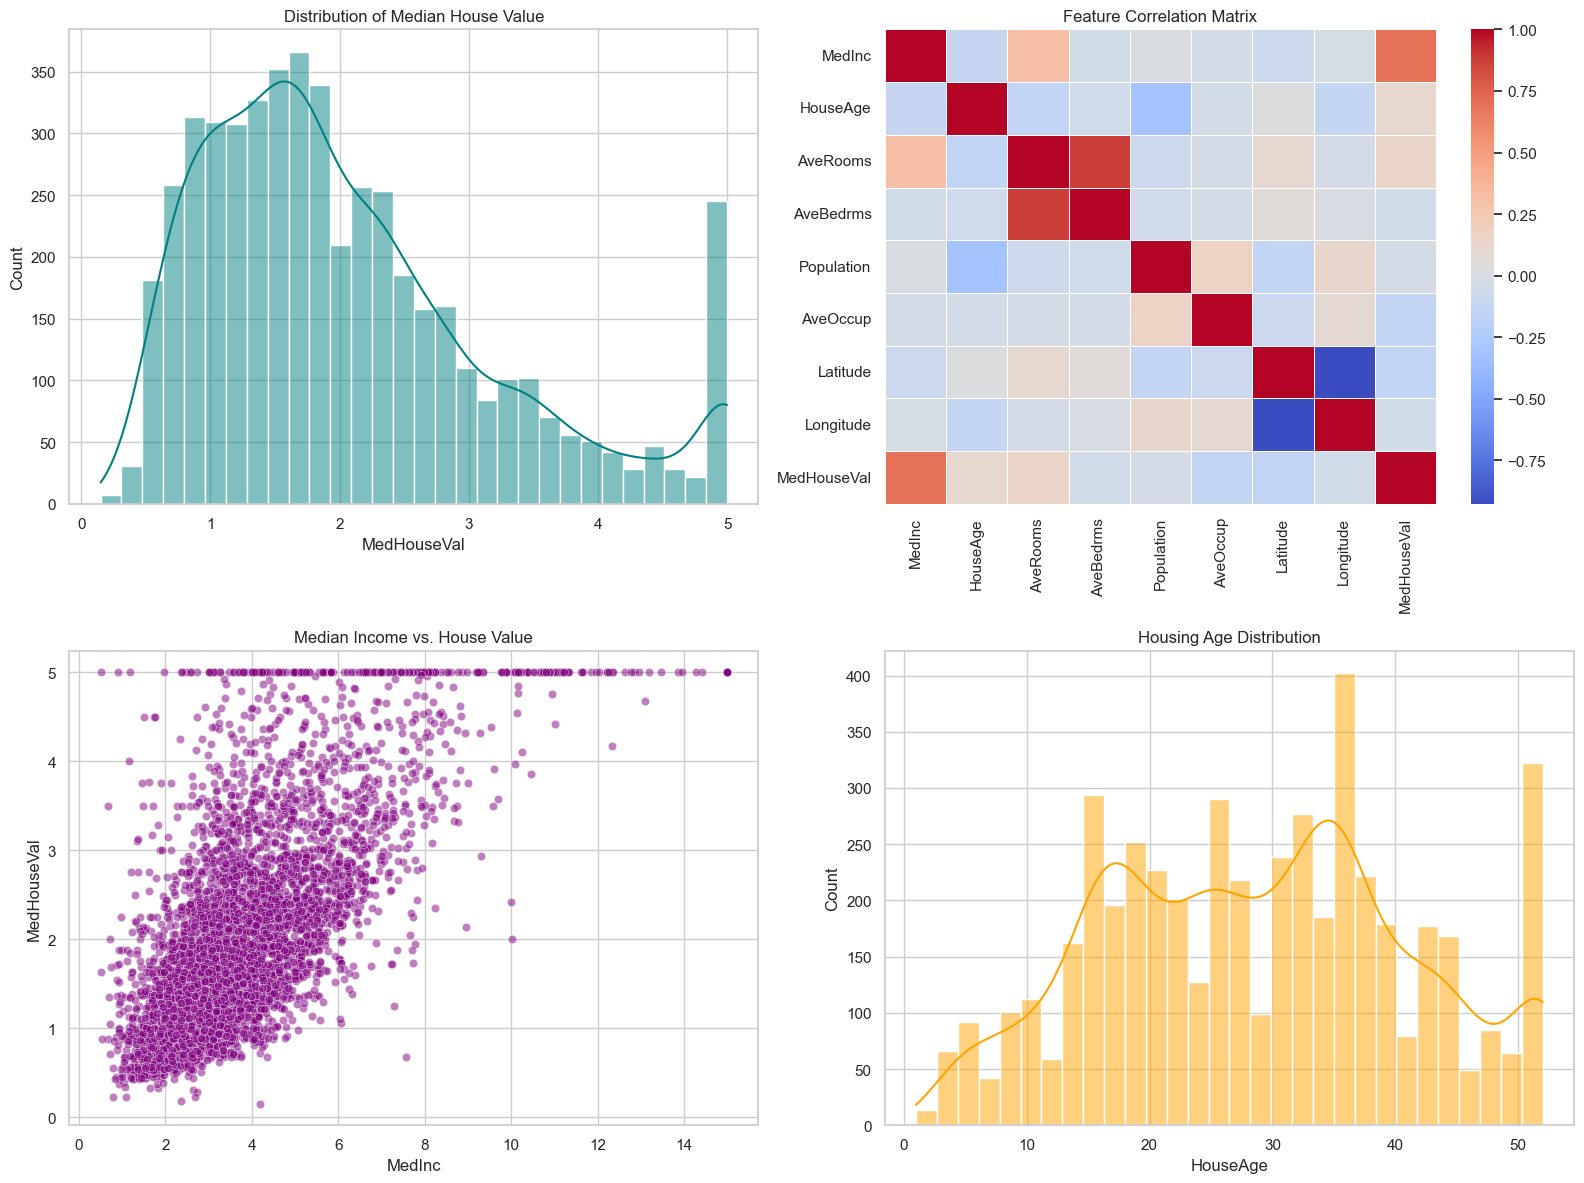

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Target Distribution (MedHouseVal)
sns.histplot(ax=axes[0, 0], data=df, x='MedHouseVal', kde=True, color='teal', bins=30)
axes[0, 0].set_title('Distribution of Median House Value')

# 2. Correlation Heatmap
corr = df.corr()
sns.heatmap(ax=axes[0, 1], data=corr, annot=False, cmap='coolwarm', linewidths=0.5)
axes[0, 1].set_title('Feature Correlation Matrix')

# 3. Median Income vs House Value
sns.scatterplot(ax=axes[1, 0], data=df, x='MedInc', y='MedHouseVal', alpha=0.5, color='purple')
axes[1, 0].set_title('Median Income vs. House Value')

# 4. House Age Distribution
sns.histplot(ax=axes[1, 1], data=df, x='HouseAge', kde=True, color='orange', bins=30)
axes[1, 1].set_title('Housing Age Distribution')

plt.tight_layout()
plt.show()

### Phase 3: Machine Learning Model Training & Evaluation

In [ ]:
# Features and Target
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rf_regressor = RandomForestRegressor(n_estimators=150, random_state=42)
rf_regressor.fit(X_train_scaled, y_train)

# Predictions
y_pred = rf_regressor.predict(X_test_scaled)

# Evaluation Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Capstone Model Evaluation Results ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared Score (R2): {r2:.4f}")

--- Capstone Model Evaluation Results ---
Root Mean Squared Error (RMSE): 0.5869
Mean Absolute Error (MAE): 0.3952
R-squared Score (R2): 0.7449


### Phase 4: Portfolio Summary & Conclusion
This concludes the End-to-End Data Science Capstone Project for Codomax Digital Solutions:
1. **Robust EDA**: Analyzed feature distributions and correlation structures.
2. **Advanced Modeling**: Trained an ensemble Random Forest Regressor achieving strong predictive performance.
3. **Production-Ready Structure**: Clean, modular code documented with markdown explanations, ready for GitHub publishing and portfolio presentation.